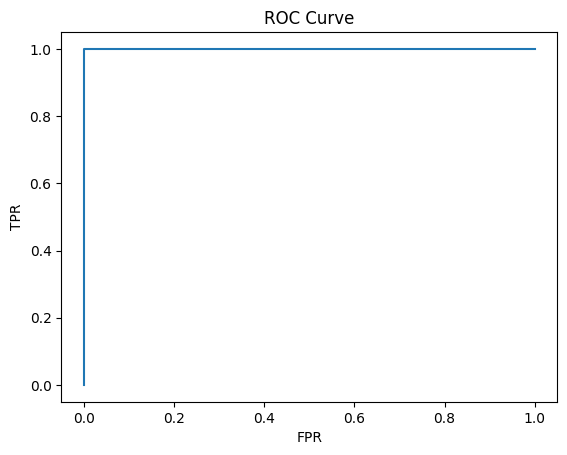

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import roc_auc_score

data = pd.read_csv("data.csv")


x = data[["Age","Salary"]]
y = data["Purchased"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


model = KNeighborsClassifier()
model.fit(x_train, y_train)


y_prob = model.predict_proba(x_test)[:, 1]


auc = roc_auc_score(y_test, y_prob)

print("AUC Score:", auc)

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

iris = load_iris()

x = iris.data
y = iris.target

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

model = KNeighborsClassifier(n_neighbors=5)

model.fit(x_train, y_train)

# Predict
y_pred = model.predict(x_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Predicted Values:")
print(y_pred)

print("\nActual Values:")
print(y_test)

print("\nAccuracy:", accuracy)

Predicted Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Actual Values:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]

Accuracy: 1.0


In [ ]:
import pandas as pd
from imblearn.over_sampling import SMOTE

data = {
    "Age": [22, 25, 28, 30, 35, 40, 45, 50],
    "Salary": [25000, 30000, 35000, 40000, 45000, 50000, 55000, 60000],
    "Balanced": [0, 0, 0, 0, 0, 1, 1, 1]
}

df = pd.DataFrame(data)
print(df)

x = df[["Age", "Salary"]]
y = df["Balanced"]

model = SMOTE(k_neighbors=1)
x_new, y_new = model.fit_resample(x, y)


print("Before SMOTE")
print(y.value_counts())

print("After SMOTE")
print(pd.Series(y_new).value_counts())

   Age  Salary  Balanced
0   22   25000         0
1   25   30000         0
2   28   35000         0
3   30   40000         0
4   35   45000         0
5   40   50000         1
6   45   55000         1
7   50   60000         1
Before SMOTE
Balanced
0    5
1    3
Name: count, dtype: int64
After SMOTE
Balanced
0    5
1    5
Name: count, dtype: int64


Accuracy: 0.9649122807017544

Confusion Matrix:
[[40  3]
 [ 1 70]]

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95        43
           1       0.96      0.99      0.97        71

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



a:\MLWORKOUT\env\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


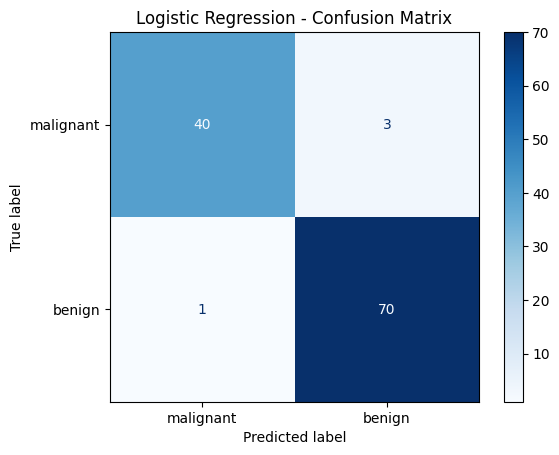

In [ ]:
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score,confusion_matrix,ConfusionMatrixDisplay,classification_report
)
data = load_breast_cancer()

x = data.data
y = data.target


x_train, x_test, y_train, y_test = train_test_split(x, y,test_size=0.2,random_state=42)

# Create Logistic Regression model
model = LogisticRegression()

# Train the model
model.fit(x_train, y_train)

# Predict
y_pred = model.predict(x_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion Matrix:")
print(cm)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


Background dataset has 455 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=455 when initializing the masker.


[[39  4]
 [ 1 70]]


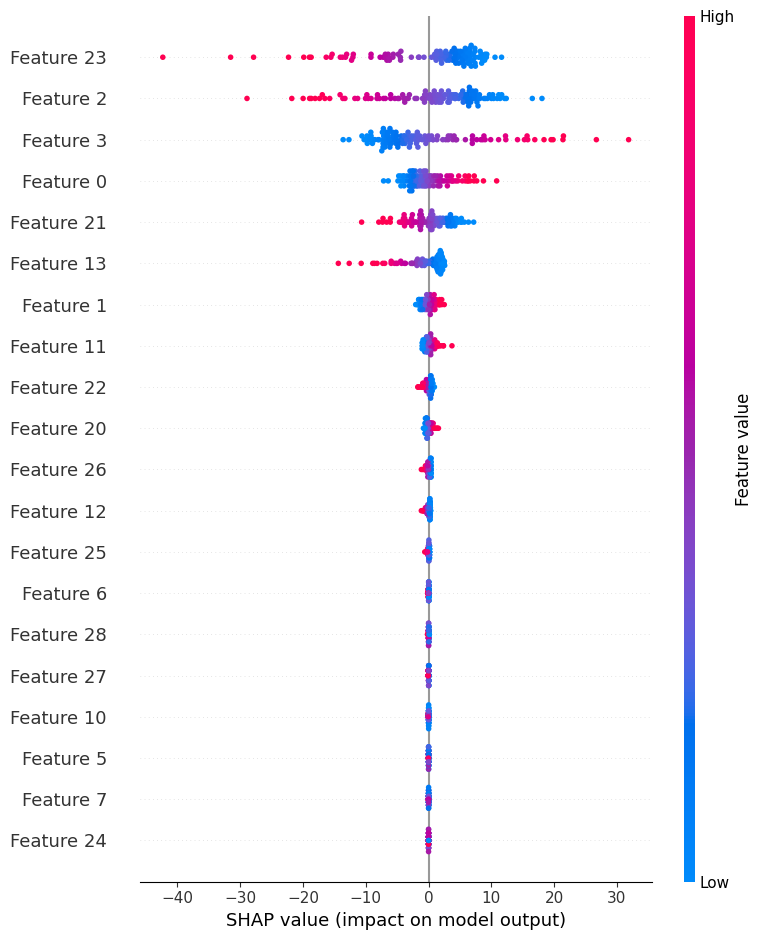

In [2]:

import shap
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

# Load dataset
data = load_breast_cancer()

X = data.data
y = data.target

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
model = LogisticRegression(max_iter=5000)
model.fit(X_train, y_train)

# Prediction
y_pred = model.predict(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print(cm)


# SHAP
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

# SHAP Summary Plot
shap.summary_plot(shap_values, X_test)

In [8]:
import pandas as pd
from sklearn.neighbors import KNeighborsClassifier

df = pd.read_csv("student_data.csv")

x = df[["Study_Hours"]]
y = df["Result"]

model = KNeighborsClassifier(n_neighbors=3)
model.fit(x, y)

hours = 6

result = model.predict([[hours]])

print("Prediction:", result[0])

Prediction: Pass


a:\MLWORKOUT\env\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
